In [65]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [66]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


**Data preparation**

In [67]:
#Making everything uniform

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [68]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [69]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [70]:
#For categorical features, replace them with 'NA'
#For numerical features, replace with with 0.0

categorical_features = df.select_dtypes(include=['object']).columns
numerical_features = df.select_dtypes(include=['number']).columns

df[categorical_features] = df[categorical_features].fillna('NA')
df[numerical_features] = df[numerical_features].fillna(0.0)

In [ ]:
df.isna().sum()

In [71]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [72]:
#Reseting the index of the dataframes

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,paid_ads,technology,employed,asia,80198.0,5,9,0.91,1
1,paid_ads,retail,employed,asia,50548.0,2,5,0.48,0
2,NA,finance,employed,NA,76300.0,0,3,0.42,0
3,paid_ads,finance,employed,NA,80371.0,2,6,0.49,0
4,organic_search,finance,employed,asia,73567.0,2,4,0.48,1


In [73]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

#Make sure that the target value converted is not in your dataframe.

del df_train['converted']
del df_val['converted']
del df_test['converted']

**Question 1: ROC AUC feature importance**

ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

lead_score
number_of_courses_viewed
interaction_count
annual_income

In [76]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train, df_train['lead_score'])

0.7882254810906102

In [77]:
roc_auc_score(y_train, df_train['number_of_courses_viewed'])

0.7229894623989618

In [78]:
roc_auc_score(y_train, df_train['interaction_count'])

0.7649203047563227

In [79]:
roc_auc_score(y_train, df_train['annual_income'])

0.6081977776250831

**Question 2: Training the model**
Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
What's the AUC of this model on the validation dataset? (round to 3 digits)

In [80]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

categorical = df_train.select_dtypes(include=['object']).columns.tolist()
numerical = df_train.select_dtypes(include=['number']).columns.tolist()

features = categorical + numerical

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
round(auc, 3)

0.732

**Question 3: Precision and Recall**
Now let's compute precision and recall for our model.

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
For each threshold, compute precision and recall
Plot them
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

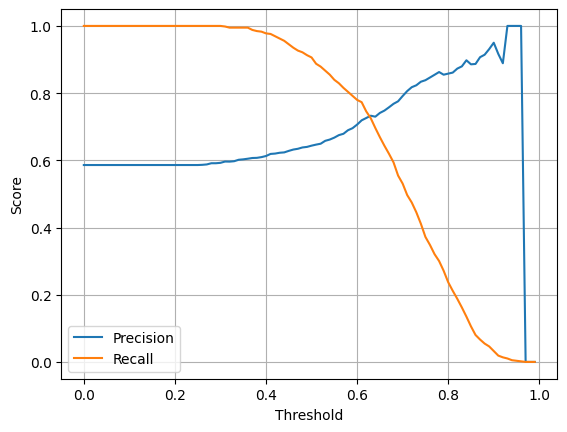

In [81]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.0, 0.01)

precisions = []
recalls = []

for t in thresholds:
    y_pred_bin = (y_pred >= t).astype(int)

    precisions.append(precision_score(y_val, y_pred_bin, zero_division=0))
    recalls.append(recall_score(y_val, y_pred_bin, zero_division=0))

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

**Question 4: F1 score**
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

F1  = 2 P R / (P + R)

Where 
P: is precision and 
R: is recall.
Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01
At which threshold F1 is maximal?

In [82]:
f1_scores = []

for p, r in zip(precisions, recalls):
    if p + r == 0:
        f1_scores.append(0)
    else:
        f1_scores.append(2 * p * r / (p + r))


best_idx = np.argmax(f1_scores)

thresholds[best_idx], f1_scores[best_idx]

(np.float64(0.41000000000000003), 0.7576158940397352)

**Question 5: 5-Fold CV**
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)
Iterate over different folds of df_full_train
Split the data into train and validation
Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
Use AUC to evaluate the model on validation
How large is standard deviation of the scores across different folds?

In [ ]:
from sklearn.model_selection import KFold
import numpy as np

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
    X_val = dv.transform(df_val[features].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

np.std(scores)

**Question 6: Hyperparameter Tuning**
Now let's use 5-Fold cross-validation to find the best parameter C

Iterate over the following C values: [0.000001, 0.001, 1]
Initialize KFold with the same parameters as previously
Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
Which C leads to the best mean ROC AUC?

In [83]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv = DictVectorizer(sparse=False)

        X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
        X_val = dv.transform(df_val[features].to_dict(orient='records'))

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(C, round(np.mean(scores), 3), round(np.std(scores), 3))

1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007
